# MMA 867: Home Credit Default Risk Model

**Professor:** Prof. Jue Wang, PhD  
**Team:** Agnes  
**Team Members:** Jason Anyimadu, Carter Chen, Mutasha Lin, Hodane Abdi, Moji Khorashahi 
**Date:** October 10, 2026

## Executive Summary

**Question.** Can application data rank applicants by default risk well enough to prioritize review effort, and which model should the lender use? Final decisions stay with policy and human judgment.

**Approach.** Compare **XGBoost** and four other models against a **logistic regression benchmark**, the standard model for a yes/no outcome, on 307,511 applicants (8.07% default rate), using an 80/20 train/test split with the test set held out until final comparison. We then test whether an explainable **binned logistic scorecard** can close the gap to XGBoost.

**Notebook structure.**
1. Setup, data overview and data quality (Sections 1-3)
2. Exploratory data analysis (Section 4)
3. Feature engineering, train/test split and preprocessing (Sections 5-6)
4. Six models, from OLS to XGBoost, judged against a logistic regression benchmark (Sections 7-8)
5. Model comparison (9.1-9.5), precision/recall/F1 (9.6), gender check (9.7) and binned logistic scorecard (9.8)
6. Conclusions and recommendations (Sections 10-11)

## 1. Import Statements/ Setup

In [4]:
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

import statsmodels.api as sm
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV, LassoCV, LogisticRegressionCV, lasso_path
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.calibration import calibration_curve
from sklearn.metrics import (r2_score, roc_auc_score, roc_curve, brier_score_loss,
                             precision_score, recall_score, f1_score, confusion_matrix)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

In [5]:
pd.options.display.float_format = '{:,.2f}'.format

## 2. Load and Inspect the Data

The training file has one row per past applicant, with `TARGET` = 1 if they had payment difficulty. (The unlabelled Kaggle test file is loaded alongside but not used for evaluation.)

> **Data note:** the training and test files (`application_train.csv` and `application_test.csv`) could not be uploaded with this submission because of their size. Download both from Kaggle: [kaggle.com/competitions/home-credit-default-risk/data](https://www.kaggle.com/competitions/home-credit-default-risk/data), and place them in a folder named `home-credit-default-risk` next to this notebook to re-run it.

In [6]:
test = pd.read_csv('application_test.csv', index_col=0)
train = pd.read_csv('application_train.csv', index_col=0)

In [7]:
print(f'Train: {train.shape}') # 307,511 applicants, 121 columns (120 features + TARGET)
print(f'Test:  {test.shape}')

Train: (307511, 121)
Test:  (48744, 120)


In [8]:
train.head()

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100002,1,Cash loans,M,N,Y,0,"202,500.00","406,597.50","24,700.50","351,000.00",...,0,0,0,0,0.00,0.00,0.00,0.00,0.00,1.00
100003,0,Cash loans,F,N,N,0,"270,000.00","1,293,502.50","35,698.50","1,129,500.00",...,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
100004,0,Revolving loans,M,Y,Y,0,"67,500.00","135,000.00","6,750.00","135,000.00",...,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00
100006,0,Cash loans,F,N,Y,0,"135,000.00","312,682.50","29,686.50","297,000.00",...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
100007,0,Cash loans,M,N,Y,0,"121,500.00","513,000.00","21,865.50","513,000.00",...,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00


In [9]:
train.dtypes.value_counts()

float64    65
int64      40
object     16
Name: count, dtype: int64

**Takeaway:** most of the 120 columns are numeric. The 16 text columns (e.g. contract type, gender, education) are converted to 0/1 dummy variables before modelling.

## 3. Data Quality

### 3.1 Missing values and duplicates

In [10]:
print(f'Any NaN values? {train.isna().values.any()}')
print(f'Any duplicate applicants? {train.index.duplicated().any()}')

Any NaN values? True
Any duplicate applicants? False


Columns with missing values: 67 of 121


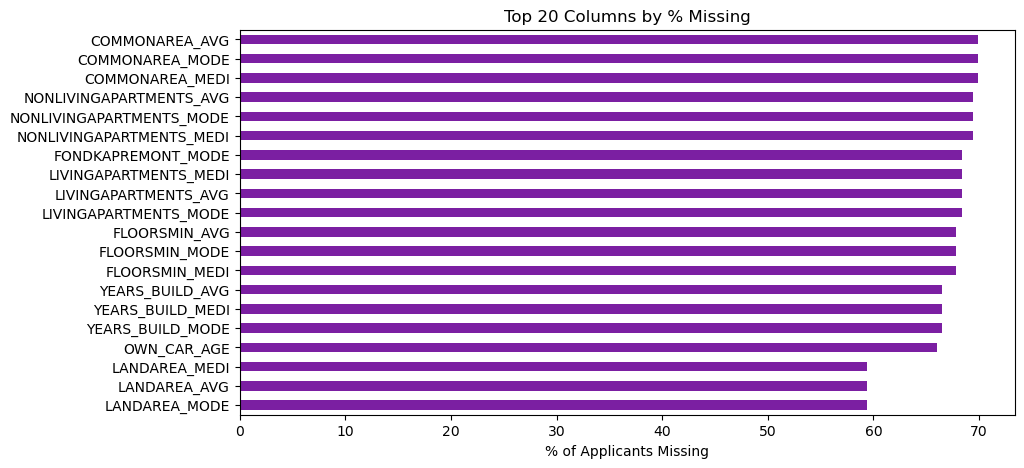

In [11]:
missing_pct = (train.isna().mean() * 100).sort_values(ascending=False)
print(f'Columns with missing values: {(missing_pct > 0).sum()} of {train.shape[1]}')

plt.figure(figsize=(10, 5), dpi=100)
missing_pct.head(20).plot(kind='barh', color='#7b1fa2')
plt.gca().invert_yaxis()
plt.title('Top 20 Columns by % Missing')
plt.xlabel('% of Applicants Missing')
plt.show()

**Takeaway:** there are no duplicate applicants, but 67 of 121 columns have gaps, led by the building-information columns (`_AVG`, `_MODE`, `_MEDI`), which are missing for over half of applicants. We don't drop these rows, because a missing value can itself signal risk. XGBoost handles gaps natively; for the linear models we fill them with the training median (Section 6).

### 3.2 Descriptive statistics

In [12]:
train[['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
       'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].describe()

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,DAYS_BIRTH,DAYS_EMPLOYED,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
count,"307,511.00","307,511.00","307,499.00","307,511.00","307,511.00","134,133.00","306,851.00","246,546.00"
mean,"168,797.92","599,026.00","27,108.57","-16,037.00","63,815.05",0.50,0.51,0.51
std,"237,123.15","402,490.78","14,493.74","4,363.99","141,275.77",0.21,0.19,0.19
min,"25,650.00","45,000.00","1,615.50","-25,229.00","-17,912.00",0.01,0.00,0.00
25%,"112,500.00","270,000.00","16,524.00","-19,682.00","-2,760.00",0.33,0.39,0.37
50%,"147,150.00","513,531.00","24,903.00","-15,750.00","-1,213.00",0.51,0.57,0.54
75%,"202,500.00","808,650.00","34,596.00","-12,413.00",-289.00,0.68,0.66,0.67
max,"117,000,000.00","4,050,000.00","258,025.50","-7,489.00","365,243.00",0.96,0.85,0.90


**Two anomalies:**
* `DAYS_BIRTH` and `DAYS_EMPLOYED` count days *before* the application, so they are negative; we convert them to positive years.
* `DAYS_EMPLOYED` has a maximum of **365,243** days (about 1,000 years): a placeholder code, not a real value (see Section 4.2).

## 4. Exploratory Data Analysis

### 4.1 The target: how many applicants default?

In [13]:
default_counts = train['TARGET'].value_counts().sort_index()
repaid, defaulted = default_counts[0], default_counts[1]

bar = px.bar(x=['Repaid (0)', 'Defaulted (1)'],
             y=default_counts.values,
             color=default_counts.values,
             text=default_counts.values,
             color_continuous_scale=px.colors.sequential.haline,
             title=f'Did the Applicant Default? Repaid: {repaid:,} | Defaulted: {defaulted:,} | Total: {default_counts.sum():,}')

bar.update_traces(texttemplate='%{text:,}', textposition='outside')
bar.update_layout(xaxis_title='Outcome',
                  yaxis_title='Number of Applicants',
                  coloraxis_showscale=False)
bar.show()

print(f"Default rate: {train['TARGET'].mean():.2%}")

Default rate: 8.07%


**Takeaway: only about 8% of applicants default.** This *imbalance* shapes the analysis:
* **Accuracy is misleading.** Predicting "nobody defaults" is 92% accurate but useless.
* **Models are judged on ranking** (ROC-AUC): how well they place risky applicants above safe ones.
* **A 0.50 probability cut-off flags almost no one**, so lower cut-offs matter in practice.

### 4.2 Key features: defaulters vs. repaid

Each chart splits applicants by `TARGET` to show whether defaulters look different.

#### Age of Applicants

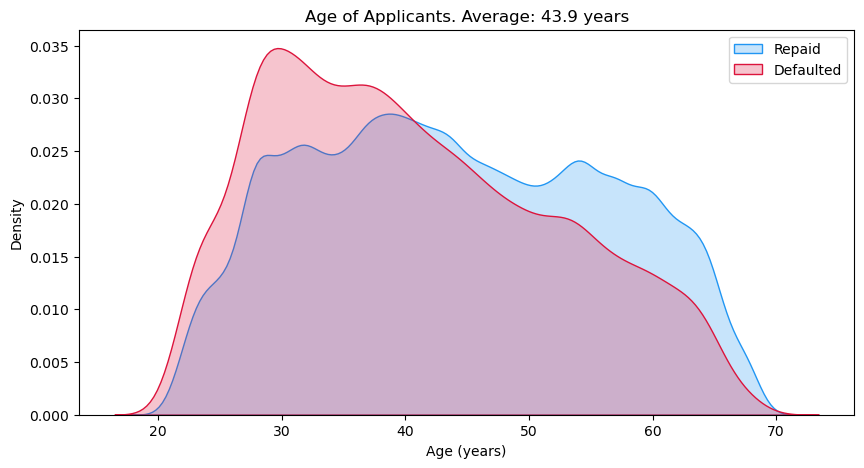

In [14]:
age_years = -train['DAYS_BIRTH'] / 365.25

plt.figure(figsize=(10, 5), dpi=100)
sns.kdeplot(age_years[train['TARGET'] == 0], label='Repaid', color='#2196f3', fill=True)
sns.kdeplot(age_years[train['TARGET'] == 1], label='Defaulted', color='crimson', fill=True)
plt.title(f'Age of Applicants. Average: {age_years.mean():.1f} years')
plt.xlabel('Age (years)')
plt.legend()
plt.show()

The defaulters' curve is shifted to the left: **younger applicants default more often**.

#### External Credit Scores

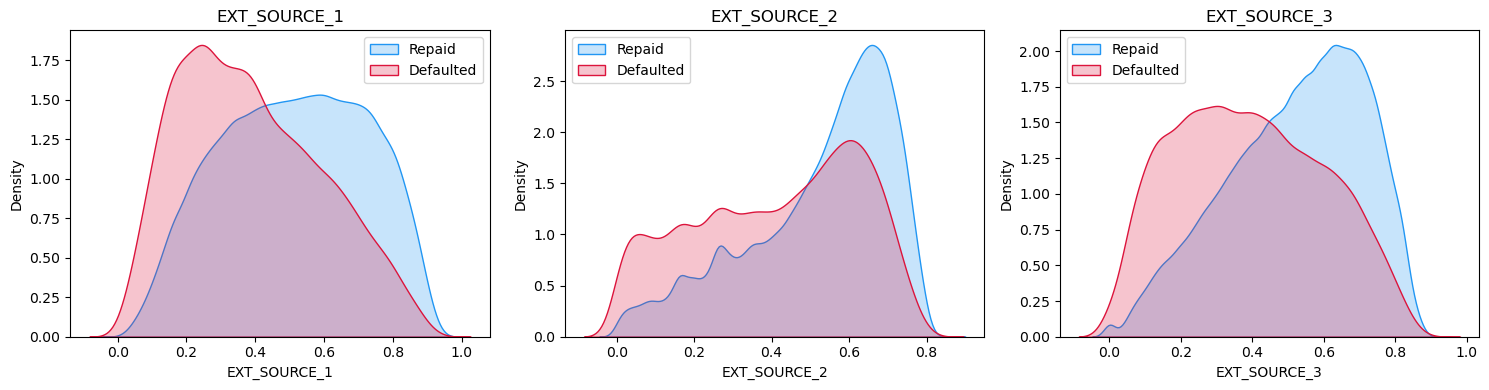

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=100)
for ax, col in zip(axes, ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):
    sns.kdeplot(train.loc[train['TARGET'] == 0, col], ax=ax, label='Repaid', color='#2196f3', fill=True)
    sns.kdeplot(train.loc[train['TARGET'] == 1, col], ax=ax, label='Defaulted', color='crimson', fill=True)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

**Takeaway:** the external scores (from credit agencies, scaled 0-1) separate the two groups more clearly than any other feature: defaulters cluster at low scores. Expect them to be the strongest predictors in every model.

#### Income

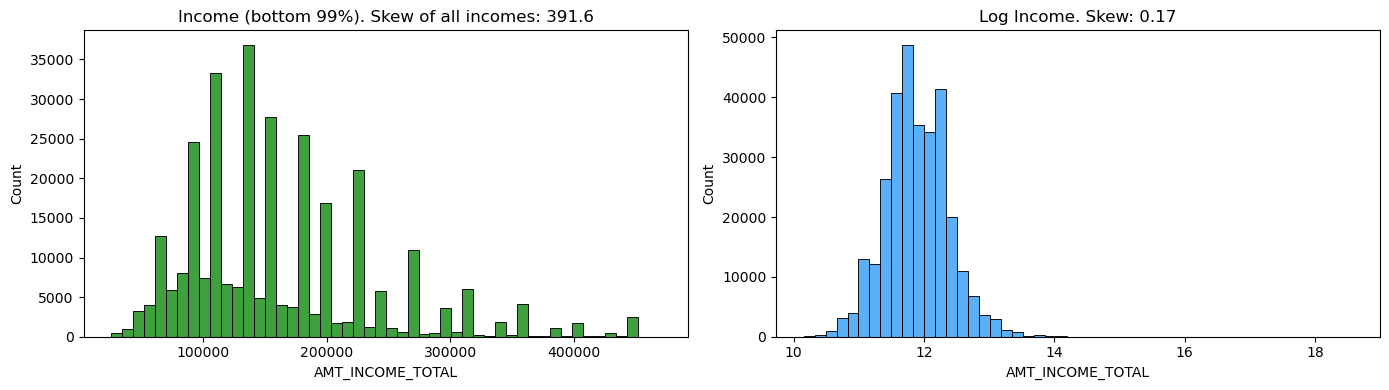

In [16]:
income = train['AMT_INCOME_TOTAL']
log_income = np.log(income)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), dpi=100)
sns.histplot(income[income < income.quantile(0.99)], bins=50, ax=axes[0], color='green')
axes[0].set_title(f'Income (bottom 99%). Skew of all incomes: {income.skew():.1f}')
sns.histplot(log_income, bins=50, ax=axes[1], color='#2196f3')
axes[1].set_title(f'Log Income. Skew: {log_income.skew():.2f}')
plt.tight_layout()
plt.show()

**Takeaway:** raw income is heavily skewed by a few very high earners; its log is nearly symmetric. Trees are unaffected by skew (they only use the order of values) but linear models are not, so Section 5 uses log amounts and ratios such as credit-to-income.

#### Days employed: the 365,243 anomaly

Applicants with DAYS_EMPLOYED = 365243: 55,374 (18.0%)
Default rate with anomaly:    5.40%
Default rate without anomaly: 8.66%


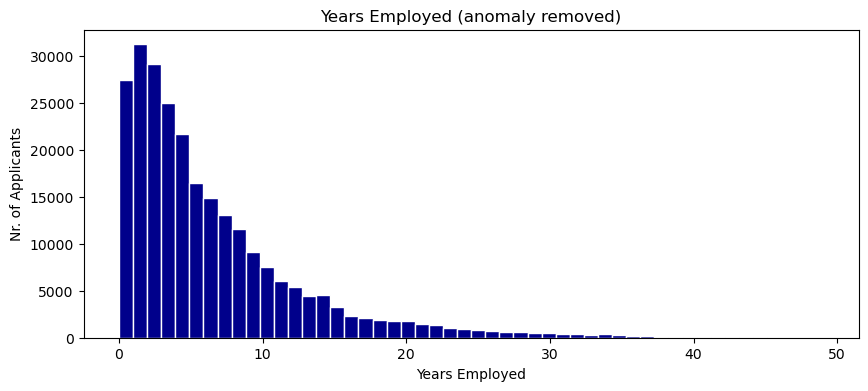

In [17]:
anomaly = train['DAYS_EMPLOYED'] == 365243
print(f'Applicants with DAYS_EMPLOYED = 365243: {anomaly.sum():,} ({anomaly.mean():.1%})')
print(f"Default rate with anomaly:    {train.loc[anomaly, 'TARGET'].mean():.2%}")
print(f"Default rate without anomaly: {train.loc[~anomaly, 'TARGET'].mean():.2%}")

plt.figure(figsize=(10, 4), dpi=100)
plt.hist(-train.loc[~anomaly, 'DAYS_EMPLOYED'] / 365.25, bins=50, color='darkblue', ec='white')
plt.title('Years Employed (anomaly removed)')
plt.xlabel('Years Employed')
plt.ylabel('Nr. of Applicants')
plt.show()

**Takeaway:** about 18% of applicants carry this code, almost all pensioners or unemployed, and they default *less* than average (5.4% vs. 8.7%). We set the value to missing and keep a 0/1 flag so the models still know these applicants are different.

### 4.3 Default rates across groups

With a 0/1 target, the clearest view is the default rate within groups of applicants.

#### Default Rate by Age Group

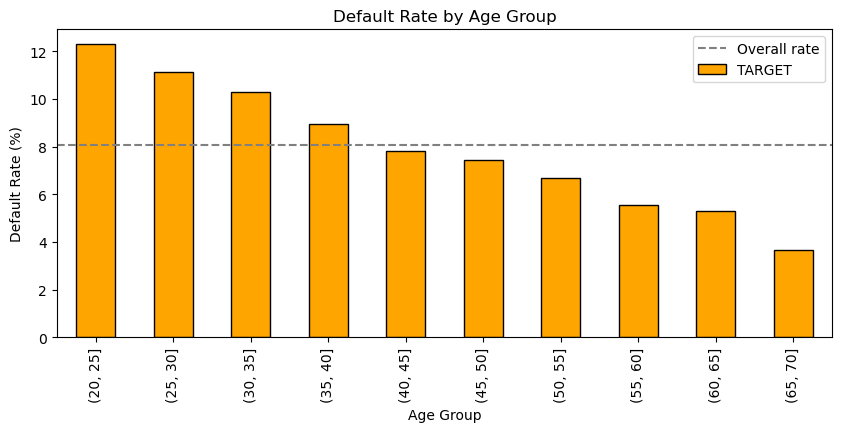

In [18]:
age_group = pd.cut(age_years, bins=[20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70])
rate_by_age = train.groupby(age_group, observed=True)['TARGET'].mean() * 100

plt.figure(figsize=(10, 4), dpi=100)
rate_by_age.plot(kind='bar', color='orange', ec='black')
plt.axhline(train['TARGET'].mean() * 100, color='gray', linestyle='--', label='Overall rate')
plt.title('Default Rate by Age Group')
plt.ylabel('Default Rate (%)')
plt.xlabel('Age Group')
plt.legend()
plt.show()

**Takeaway:** a steady downward slope: about 12% of applicants aged 20-25 default, roughly three times the rate of those aged 65-70 (under 4%).

#### Default Rate by External Score Decile

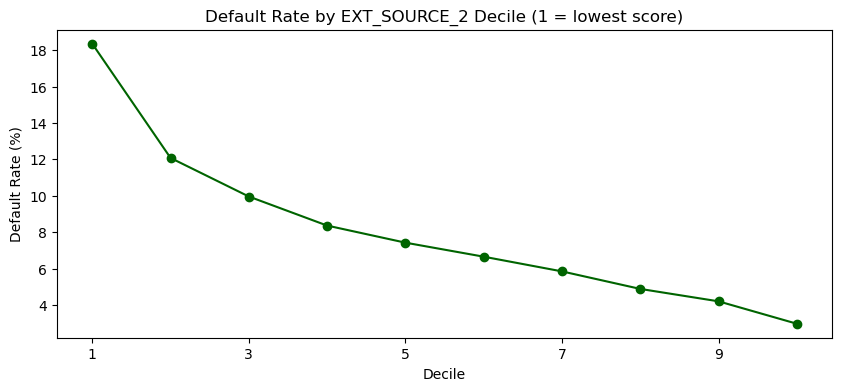

In [19]:
ext2_decile = pd.qcut(train['EXT_SOURCE_2'], 10, labels=range(1, 11))
rate_by_ext2 = train.groupby(ext2_decile, observed=True)['TARGET'].mean() * 100

plt.figure(figsize=(10, 4), dpi=100)
rate_by_ext2.plot(marker='o', color='darkgreen')
plt.title('Default Rate by EXT_SOURCE_2 Decile (1 = lowest score)')
plt.ylabel('Default Rate (%)')
plt.xlabel('Decile')
plt.show()

**Takeaway:** default falls steadily from the lowest to the highest `EXT_SOURCE_2` decile, the clearest single-feature pattern in the data.

#### Default Rate by Education

In [20]:
rate_by_edu = (train.groupby('NAME_EDUCATION_TYPE')['TARGET']
                    .agg(['mean', 'size'])
                    .sort_values('mean', ascending=False))
rate_by_edu['mean'] *= 100
rate_by_edu.columns = ['Default Rate (%)', 'Applicants']
rate_by_edu

,Default Rate (%),Applicants
NAME_EDUCATION_TYPE,,
Lower secondary,10.93,3816
Secondary / secondary special,8.94,218391
Incomplete higher,8.48,10277
Higher education,5.36,74863
Academic degree,1.83,164


**Takeaway:** default falls with education, from 10.9% (lower secondary) to 5.4% (higher education) and 1.8% for the 164 applicants with an academic degree.

#### Which Features Are Most Correlated with Default?

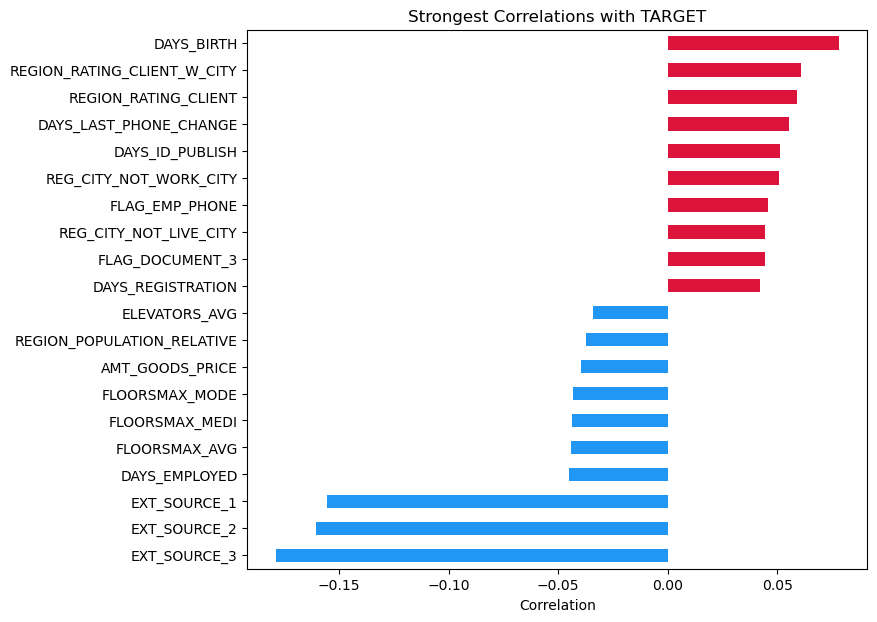

In [21]:
correlations = train.select_dtypes('number').corr()['TARGET'].drop('TARGET').sort_values()
top_corr = pd.concat([correlations.head(10), correlations.tail(10)])

plt.figure(figsize=(8, 7), dpi=100)
top_corr.plot(kind='barh', color=np.where(top_corr > 0, 'crimson', '#2196f3'))
plt.title('Strongest Correlations with TARGET')
plt.xlabel('Correlation')
plt.show()

**Takeaway:** the external scores have the strongest (negative) correlations. Still, every correlation is below 0.2 in absolute value: no single feature predicts default on its own, which is why the models combine many.

## 5. Feature Engineering

We turn the raw application fields into signals a lender would recognise: affordability (loan size vs. income, repayment burden), job stability, and one combined external credit score. Details are in the code comments.

In [22]:
# Turn raw application fields into signals a lender would recognise.
# Written as one function so new applicants get exactly the same treatment.
MONEY_COLS = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
EXT_COLS = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

def engineer_features(df):
    df = df.copy()

    # 1. DAYS_EMPLOYED = 365243 is a placeholder (mostly pensioners): keep a 0/1 flag, then set it to missing
    df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)
    df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)

    # 2. Negative day counts -> positive years (easier to read)
    df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365.25
    df['YEARS_EMPLOYED'] = -df['DAYS_EMPLOYED'] / 365.25

    # 3. Affordability: what matters is the loan RELATIVE to the borrower's means
    #    CREDIT_TERM = yearly repayment / loan (higher = shorter loan, paid off faster)
    df['CREDIT_INCOME_RATIO'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
    df['ANNUITY_INCOME_RATIO'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    df['CREDIT_TERM'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    df['GOODS_CREDIT_RATIO'] = df['AMT_GOODS_PRICE'] / df['AMT_CREDIT']
    df['EMPLOYED_AGE_RATIO'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']

    # 4. Log of money amounts: tames the few very large values (helps the linear models); raw amounts dropped
    for col in MONEY_COLS:
        df['LOG_' + col] = np.log1p(df[col])
    df = df.drop(columns=MONEY_COLS + ['DAYS_BIRTH', 'DAYS_EMPLOYED'])

    # 5. External credit scores, our strongest signal: combine the three, and flag when one is missing
    ext = df[EXT_COLS]
    df['EXT_SOURCE_MEAN'] = ext.mean(axis=1)
    df['EXT_SOURCE_MIN'] = ext.min(axis=1)
    df['EXT_SOURCE_MAX'] = ext.max(axis=1)
    df['EXT_SOURCE_STD'] = ext.std(axis=1)
    df['EXT_SOURCE_COUNT'] = ext.notna().sum(axis=1)
    for col in EXT_COLS:
        df[col + '_MISSING'] = df[col].isna().astype(int)

    # 6. Number of documents provided (condenses 20 separate flags)
    doc_cols = [c for c in df.columns if c.startswith('FLAG_DOCUMENT_')]
    df['DOCUMENT_COUNT'] = df[doc_cols].sum(axis=1)

    return df.replace([np.inf, -np.inf], np.nan)

### 5.1 Drop redundant and mostly-empty columns

In [23]:
# Remove the 4 applicants with gender 'XNA' (none in the Kaggle test file)
train_fe = engineer_features(train[train['CODE_GENDER'] != 'XNA'])

# Building info comes in 3 near-identical versions (_AVG/_MODE/_MEDI): keep only _AVG,
# because near-duplicate columns make the linear models' coefficients unstable
numeric_cols = train_fe.select_dtypes('number').columns
dup_building = [c for c in numeric_cols if c.endswith(('_MODE', '_MEDI'))]

# Drop columns that are more than 60% empty
missing_share = train_fe.isna().mean()
mostly_missing = missing_share[missing_share > 0.60].index.difference(['TARGET']).tolist()

drop_cols = sorted(set(dup_building + mostly_missing))
train_fe = train_fe.drop(columns=drop_cols)

print(f'Dropped {len(drop_cols)} columns ({len(dup_building)} duplicate building stats, '
      f'{len(mostly_missing)} >60% missing)')
print(f'Data after feature engineering: {train_fe.shape}')

Dropped 36 columns (29 duplicate building stats, 17 >60% missing)
Data after feature engineering: (307507, 101)


**Takeaway:** 36 columns removed, mostly duplicate or near-empty building information. We keep 101 columns for 307,507 applicants.

## 6. Train/Test Split and Preprocessing

We set aside 20% of applicants as a test set. No model sees them until Section 9, so the test results show how each model would do on new applicants.

In [24]:
QUICK_RUN = False          # True = fast 60k-row sample for development
TUNE_N = 60_000            # rows used for tuning the slower tree models
RANDOM_STATE = 10

# Hold out 20% of applicants as a test set; no model sees them until Section 9.
# 'stratify' keeps the 8% default rate the same in both parts.
model_data = train_fe.sample(60_000, random_state=RANDOM_STATE) if QUICK_RUN else train_fe

target = model_data['TARGET']
features = model_data.drop(columns='TARGET')

X_train_raw, X_test_raw, y_train, y_test = train_test_split(features, target,
                                                            test_size=0.2,
                                                            random_state=RANDOM_STATE,
                                                            stratify=target)

print(f'Training data: {len(X_train_raw):,} rows ({100*len(X_train_raw)/len(features):.3}%), '
      f'default rate {y_train.mean():.2%}')
print(f'Test data:     {len(X_test_raw):,} rows ({100*len(X_test_raw)/len(features):.3}%), '
      f'default rate {y_test.mean():.2%}')

Training data: 246,005 rows (80.0%), default rate 8.07%
Test data:     61,502 rows (20.0%), default rate 8.07%


### 6.1 Preprocessing

Linear models need a complete numeric table, so we fill gaps, turn text categories into 0/1 columns and cap extreme values. Every rule is learned from the training data only.

In [25]:
# Linear models need a complete numeric table. Every rule below is learned from the
# TRAINING data only and then applied unchanged to the test data (no peeking at the test set):
#   - text categories -> 0/1 columns (most common level is the baseline)
#   - missing values  -> training median
#   - extreme values  -> capped at the 0.5th / 99.5th percentiles
#   - constant columns removed
class Preprocessor:
    """Dummies + median imputation + winsorising, learned from the training data."""

    def fit(self, X):
        self.cat_cols = X.select_dtypes(exclude='number').columns.tolist()
        self.baseline = {c: X[c].fillna('Missing').mode()[0] for c in self.cat_cols}
        X_d = self._dummies(X)
        drop_base = [f'{c}_{b}' for c, b in self.baseline.items()]
        self.columns = [c for c in X_d.columns if c not in drop_base]
        X_d = X_d[self.columns]

        self.medians = X_d.median()
        X_d = X_d.fillna(self.medians)
        self.cont_cols = [c for c in X_d.columns if X_d[c].nunique() > 2]
        self.lower = X_d[self.cont_cols].quantile(0.005)
        self.upper = X_d[self.cont_cols].quantile(0.995)
        X_d[self.cont_cols] = X_d[self.cont_cols].clip(self.lower, self.upper, axis=1)
        self.keep = X_d.columns[X_d.std() > 0].tolist()
        return self

    def _dummies(self, X):
        X = X.copy()
        for c in self.cat_cols:
            X[c] = X[c].fillna('Missing').astype(str)
        return pd.get_dummies(X, columns=self.cat_cols, dtype=np.float32)

    def transform(self, X):
        X_d = self._dummies(X).reindex(columns=self.columns, fill_value=0)
        X_d = X_d.fillna(self.medians)
        X_d[self.cont_cols] = X_d[self.cont_cols].clip(self.lower, self.upper, axis=1)
        return X_d[self.keep].astype(np.float64)

prep = Preprocessor().fit(X_train_raw)
X_train = prep.transform(X_train_raw)
X_test = prep.transform(X_test_raw)

feature_names = X_train.columns
print(f'Model matrix: {X_train.shape[1]} features')
print(f'X_train {X_train.shape} | X_test {X_test.shape}')

Model matrix: 209 features
X_train (246005, 209) | X_test (61502, 209)


## 7. How We Evaluate the Models

Each model gives every applicant a probability of default. On the test set we ask three questions:
* **Does it rank risk well?** AUC: the chance a real defaulter is scored riskier than a good borrower (0.5 = coin flip, 1.0 = perfect).
* **Are the probabilities believable?** Brier score: the average gap between predicted risk and what actually happened (lower is better).
* **How good are its actual flags?** AUC only measures ranking, and with 8% of applicants defaulting it can look strong even when most flagged applicants turn out fine. So once a cut-off is chosen we also report **precision** (share of flagged applicants who actually default), **recall** (share of all defaulters who get flagged) and **F1** (the balance of the two). We use two cut-offs: the default 0.50 probability, and flagging the riskiest 20% of applicants.
* **Does it hold up on new applicants?** A big gap between training and test AUC means the model memorised the training data.

**Benchmark:** logistic regression (Section 8.4). The target is a 0/1 outcome (defaulted or not), and logistic regression is the standard model for that: every prediction is a real probability, and it is the industry-standard credit scorecard. Every other model has to beat it to justify its extra complexity.

OLS, Ridge and LASSO are included as *linear probability models*: they treat the 0/1 target as if it were continuous, which is simple and easy to read, but lets some predictions fall below 0 or above 1.

In [26]:
# Only create these once, so re-running this cell doesn't wipe scores already saved
if 'results' not in globals():
    results = {}        # model name -> metrics
if 'test_preds' not in globals():
    test_preds = {}     # model name -> test-set predictions (for ROC curves later)

# Scores every model the same way and saves the results for Section 9:
#   AUC   = how well it ranks risky applicants above safe ones (0.5 = coin flip, 1.0 = perfect)
#   Gini  = 2 x AUC - 1, the scale credit teams use
#   Brier = average gap between predicted risk and what happened (lower = more believable probabilities)
#   R²    = share of the variation in default explained
#   Precision / Recall / F1 = quality of the actual flags, at the 0.50 cut-off and when flagging the riskiest 20%
def flag_scores(pred):
    """Precision, recall and F1 at the 0.50 cut-off and for the riskiest 20% of applicants."""
    pred = np.asarray(pred, dtype=float)
    flags = {'@0.50': (pred >= 0.5).astype(int),
             # rank breaks ties, so exactly 20% are flagged (same grouping as the deciles in Section 9.5)
             '@top 20%': (pd.Series(pred).rank(method='first') > 0.8 * len(pred)).astype(int).values}
    out = {}
    for label, flag in flags.items():
        out[f'Precision {label}'] = precision_score(y_test, flag, zero_division=0)
        out[f'Recall {label}'] = recall_score(y_test, flag)
        out[f'F1 {label}'] = f1_score(y_test, flag, zero_division=0)
    return out

def evaluate(name, pred_train, pred_test, n_features, notes=''):
    """Score a model on train and test data and store the results."""
    pred_train, pred_test = np.asarray(pred_train), np.asarray(pred_test)
    auc_test = roc_auc_score(y_test, pred_test)
    results[name] = {
        'Train R²': r2_score(y_train, pred_train),
        'Test R²': r2_score(y_test, pred_test),
        'Train AUC': roc_auc_score(y_train, pred_train),
        'Test AUC': auc_test,
        'Test Gini': 2 * auc_test - 1,
        'Test Brier': brier_score_loss(y_test, np.clip(pred_test, 0, 1)),
        **flag_scores(pred_test),
        'Features used': n_features,
        'Notes': notes,
    }
    test_preds[name] = pred_test
    r = results[name]
    print(f"{name}:  Test AUC {r['Test AUC']:.4f} | Test R² {r['Test R²']:.4f} | "
          f"Brier {r['Test Brier']:.4f} | Train AUC {r['Train AUC']:.4f}")
    print(f"      Precision / Recall / F1 @0.50: {r['Precision @0.50']:.3f} / {r['Recall @0.50']:.3f} / {r['F1 @0.50']:.3f}  |  "
          f"riskiest 20%: {r['Precision @top 20%']:.3f} / {r['Recall @top 20%']:.3f} / {r['F1 @top 20%']:.3f}")

## 8. The Models

### 8.1 OLS (linear probability model)

The simplest model: predicted risk is a weighted sum of the applicant's features. Fitting OLS to a 0/1 target is called a linear probability model; it is easy to read but, unlike logistic regression, nothing keeps its predictions between 0 and 1.

In [27]:
start = time.time()
X_train_c = sm.add_constant(X_train, has_constant='add')
X_test_c = sm.add_constant(X_test, has_constant='add')

# Plain OLS on all features. Robust (HC1) standard errors, because with a 0/1 target
# the error spread changes with the predicted risk
ols = sm.OLS(y_train, X_train_c).fit(cov_type='HC1')
ols_pred_train = ols.predict(X_train_c)
ols_pred_test = ols.predict(X_test_c)
print(f'Fit time: {time.time() - start:.1f}s')
print(f'Training R-squared: {ols.rsquared:.4f}   (adjusted: {ols.rsquared_adj:.4f})')

evaluate('1. OLS', ols_pred_train, ols_pred_test, X_train.shape[1],
         'All features, no regularisation')

Fit time: 4.9s
Training R-squared: 0.0677   (adjusted: 0.0669)
1. OLS:  Test AUC 0.7480 | Test R² 0.0657 | Brier 0.0691 | Train AUC 0.7516
      Precision / Recall / F1 @0.50: 1.000 / 0.000 / 0.000  |  riskiest 20%: 0.203 / 0.502 / 0.289


#### Do the coefficients make sense?

In [28]:
# Sign check against the EDA: a negative coefficient lowers predicted default risk
for feat in ['EXT_SOURCE_MEAN', 'AGE_YEARS', 'CREDIT_TERM', 'NAME_EDUCATION_TYPE_Higher education']:
    if feat in ols.params:
        print(f'{feat:40s} coef = {ols.params[feat]:+.5f}  (p = {ols.pvalues[feat]:.3g})')

age_effect = ols.params.get('AGE_YEARS', np.nan) * 10
print(f'\nHolding everything else fixed, 10 extra years of age changes the predicted '
      f'default probability by {age_effect*100:+.2f} percentage points.')

EXT_SOURCE_MEAN                          coef = -0.18729  (p = 5.78e-08)
AGE_YEARS                                coef = -0.00037  (p = 0.000278)
CREDIT_TERM                              coef = -1.70338  (p = 1.56e-56)
NAME_EDUCATION_TYPE_Higher education     coef = -0.01378  (p = 1.42e-25)

Holding everything else fixed, 10 extra years of age changes the predicted default probability by -0.37 percentage points.


**Takeaway:** the key signs match the EDA: higher external scores, older age and higher education all lower predicted risk; 10 extra years of age lowers predicted default by about 0.4 percentage points. (`CREDIT_TERM` also has a negative sign, but it overlaps heavily with the loan, annuity and goods-price features, so its coefficient should not be read on its own; see Section 8.4.) The catch: OLS gives about 12% of applicants a predicted risk below 0% or above 100%, which isn't a real probability (Section 9.2). Each of the next models fixes one weakness: Ridge and LASSO steady the coefficients, logistic regression keeps predictions between 0 and 1, and the tree models capture curves and interactions.

### 8.2 Ridge regression

Ridge shrinks every coefficient a little, which steadies the model when features overlap (e.g. income and loan amount).

In [29]:
start = time.time()
ridge_alphas = np.logspace(-1, 5, 40)
# Ridge = OLS plus a penalty that shrinks every coefficient a little.
# Features are standardised so the penalty treats them equally; penalty strength picked by cross-validation
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=ridge_alphas))
ridge.fit(X_train, y_train)
best_ridge_alpha = ridge[-1].alpha_
print(f'Best alpha: {best_ridge_alpha:,.2f}   (fit time {time.time()-start:.1f}s)')

evaluate('2. Ridge', ridge.predict(X_train), ridge.predict(X_test), X_train.shape[1],
         f'alpha = {best_ridge_alpha:,.1f}')

Best alpha: 10.00   (fit time 15.6s)
2. Ridge:  Test AUC 0.7480 | Test R² 0.0657 | Brier 0.0691 | Train AUC 0.7516
      Precision / Recall / F1 @0.50: 0.000 / 0.000 / 0.000  |  riskiest 20%: 0.203 / 0.502 / 0.289


**Takeaway:** identical to OLS (AUC 0.748). With 246,000 training applicants, OLS wasn't overfitting, so shrinking adds nothing.

### 8.3 LASSO

LASSO can switch weak features off entirely, which gives a shorter model.

In [30]:
start = time.time()
# LASSO = OLS plus a penalty that can switch weak features off entirely (coefficient exactly 0)
Xs_train = StandardScaler().fit_transform(X_train)   # standardised copy, used to set the penalty range
# Alpha grid: from alpha_max (every coefficient = 0) down to alpha_max / 10,000
alpha_max = np.abs(Xs_train.T @ (y_train.values - y_train.mean())).max() / len(y_train)
lasso_alphas = np.logspace(np.log10(alpha_max), np.log10(alpha_max * 1e-4), 40)

lasso = make_pipeline(StandardScaler(),
                      LassoCV(alphas=lasso_alphas, cv=5, random_state=RANDOM_STATE,
                              n_jobs=-1, max_iter=5000))
lasso.fit(X_train, y_train)
lasso_cv = lasso[-1]
lasso_coef = pd.Series(lasso_cv.coef_, index=feature_names)
n_selected = int((lasso_coef != 0).sum())

print(f'Best alpha: {lasso_cv.alpha_:.6f}   (fit time {time.time()-start:.1f}s)')
print(f'LASSO kept {n_selected} of {len(lasso_coef)} features '
      f'and set {len(lasso_coef) - n_selected} to exactly zero')

evaluate('3. LASSO', lasso.predict(X_train), lasso.predict(X_test), n_selected,
         f'alpha = {lasso_cv.alpha_:.5f}')

Best alpha: 0.000051   (fit time 80.6s)
LASSO kept 191 of 209 features and set 18 to exactly zero
3. LASSO:  Test AUC 0.7480 | Test R² 0.0657 | Brier 0.0691 | Train AUC 0.7515
      Precision / Recall / F1 @0.50: 0.000 / 0.000 / 0.000  |  riskiest 20%: 0.203 / 0.503 / 0.289


**Takeaway:** LASSO switched off only 18 of 209 features and matched OLS (AUC 0.748). Almost every feature carries a little signal, so there is no short scorecard hiding in the data.

### 8.4 Logistic regression (the benchmark)

The standard model for a 0/1 outcome and the industry-standard credit scorecard, so it is the benchmark every other model must beat. It bends the weighted sum into an S-curve, so every prediction is a real probability between 0 and 1.

In [31]:
start = time.time()
# Logistic regression: the industry-standard credit scorecard. Every prediction is a
# real probability between 0 and 1. Penalty strength C picked by 3-fold cross-validation on AUC
logit = make_pipeline(StandardScaler(),
                      LogisticRegressionCV(Cs=[0.001, 0.01, 0.1, 1, 10], scoring='roc_auc', max_iter=2000,
                                           cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)))
logit.fit(X_train, y_train)
best_C = logit[-1].C_[0]
print(f'Best C: {best_C}   (fit time {time.time()-start:.1f}s)')

logit_pred_train = logit.predict_proba(X_train)[:, 1]
logit_pred_test = logit.predict_proba(X_test)[:, 1]
evaluate('4. Logistic Regression (benchmark)', logit_pred_train, logit_pred_test, X_train.shape[1], f'L2 penalty, C = {best_C}')

Best C: 1.0   (fit time 13.0s)
4. Logistic Regression (benchmark):  Test AUC 0.7498 | Test R² 0.0794 | Brier 0.0683 | Train AUC 0.7544
      Precision / Recall / F1 @0.50: 0.509 / 0.011 / 0.022  |  riskiest 20%: 0.205 / 0.509 / 0.292


#### What raises and lowers the odds of default?

Each bar shows how the odds of default change when a feature rises by one standard deviation: below 1 lowers risk (blue), above 1 raises it (red).

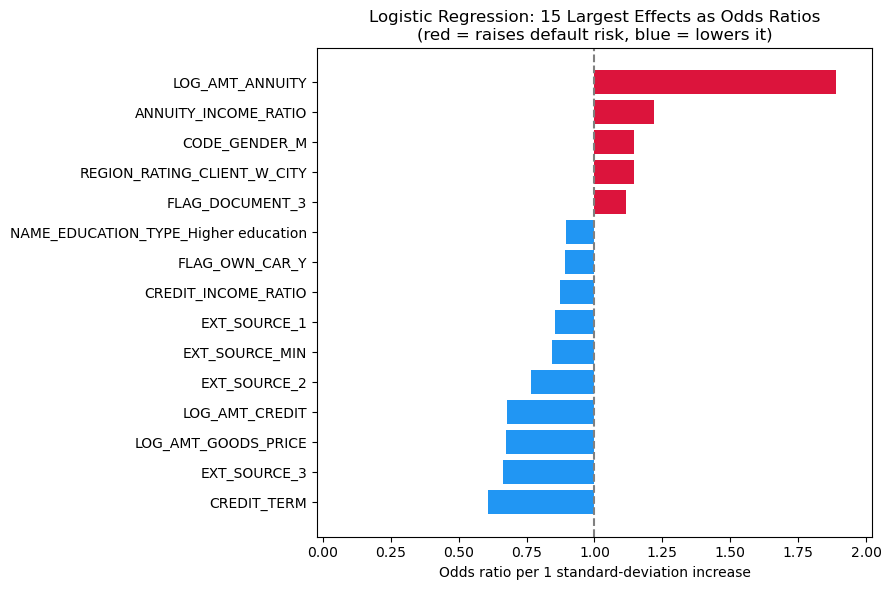

Strongest protective factor: CREDIT_TERM (odds x0.61 per 1 SD, i.e. 39% lower odds of default)
Strongest risk factor:       LOG_AMT_ANNUITY (odds x1.89 per 1 SD, i.e. 89% higher odds of default)


In [32]:
logit_coef = pd.Series(logit[-1].coef_[0], index=feature_names)
odds_ratio = np.exp(logit_coef)   # 0.60 = 40% lower odds of default; 1.20 = 20% higher
top_or = odds_ratio.loc[logit_coef.abs().sort_values(ascending=False).head(15).index].sort_values()

plt.figure(figsize=(9, 6), dpi=100)
plt.barh(top_or.index, top_or.values - 1, left=1, color=np.where(top_or > 1, 'crimson', '#2196f3'))  # bars run from 1 to the odds ratio
plt.axvline(1, color='gray', linestyle='--')
span = (top_or - 1).abs().max() * 1.15
plt.xlim(1 - span, 1 + span)
plt.title('Logistic Regression: 15 Largest Effects as Odds Ratios\n(red = raises default risk, blue = lowers it)')
plt.xlabel('Odds ratio per 1 standard-deviation increase')
plt.tight_layout()
plt.show()

lowest, highest = odds_ratio.idxmin(), odds_ratio.idxmax()
print(f'Strongest protective factor: {lowest} (odds x{odds_ratio[lowest]:.2f} per 1 SD, '
      f'i.e. {1 - odds_ratio[lowest]:.0%} lower odds of default)')
print(f'Strongest risk factor:       {highest} (odds x{odds_ratio[highest]:.2f} per 1 SD, '
      f'i.e. {odds_ratio[highest] - 1:.0%} higher odds of default)')

**Takeaway:** logistic regression edges out OLS (AUC 0.750 vs. 0.748). External scores, higher education and owning a car lower the odds of default; male gender and a weaker regional rating raise them. The largest odds ratios belong to `LOG_AMT_ANNUITY` (1.89) and `CREDIT_TERM` (0.61).

**Caution:** several affordability features are near-copies of each other (`CREDIT_TERM` is the yearly repayment divided by the loan amount, and loan amount and goods price move almost together). These two odds ratios therefore describe overlapping information and partly cancel, so they should be read together, not one at a time. The binned scorecard in Section 9.8 drops the duplicates and lets repayment speed bend instead of forcing a straight line.

### 8.5 Regression tree

A tree sorts applicants into groups with simple yes/no rules and predicts each group's default rate. Easy to explain, but coarse.

In [33]:
# Tune tree depth and minimum group size on a 60,000-applicant sample (to save time),
# then refit the chosen tree on all training applicants
tune_idx = X_train.sample(min(TUNE_N, len(X_train)), random_state=RANDOM_STATE).index
X_tune, y_tune = X_train.loc[tune_idx], y_train.loc[tune_idx]

start = time.time()
tree_grid = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                         param_grid={'max_depth': [3, 4, 5, 6, 8, 10],
                                     'min_samples_leaf': [50, 200, 500, 1000]},
                         cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
tree_grid.fit(X_tune, y_tune)
print(f'Best tree settings: {tree_grid.best_params_}   (tuning time {time.time()-start:.1f}s)')

tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **tree_grid.best_params_).fit(X_train, y_train)
evaluate('5. Regression Tree', tree.predict(X_train), tree.predict(X_test),
         int((tree.feature_importances_ > 0).sum()),
         f"depth {tree_grid.best_params_['max_depth']}, min leaf {tree_grid.best_params_['min_samples_leaf']}")

Best tree settings: {'max_depth': 8, 'min_samples_leaf': 1000}   (tuning time 39.1s)
5. Regression Tree:  Test AUC 0.7253 | Test R² 0.0623 | Brier 0.0696 | Train AUC 0.7440
      Precision / Recall / F1 @0.50: 0.000 / 0.000 / 0.000  |  riskiest 20%: 0.192 / 0.476 / 0.274


#### Visualise the tree

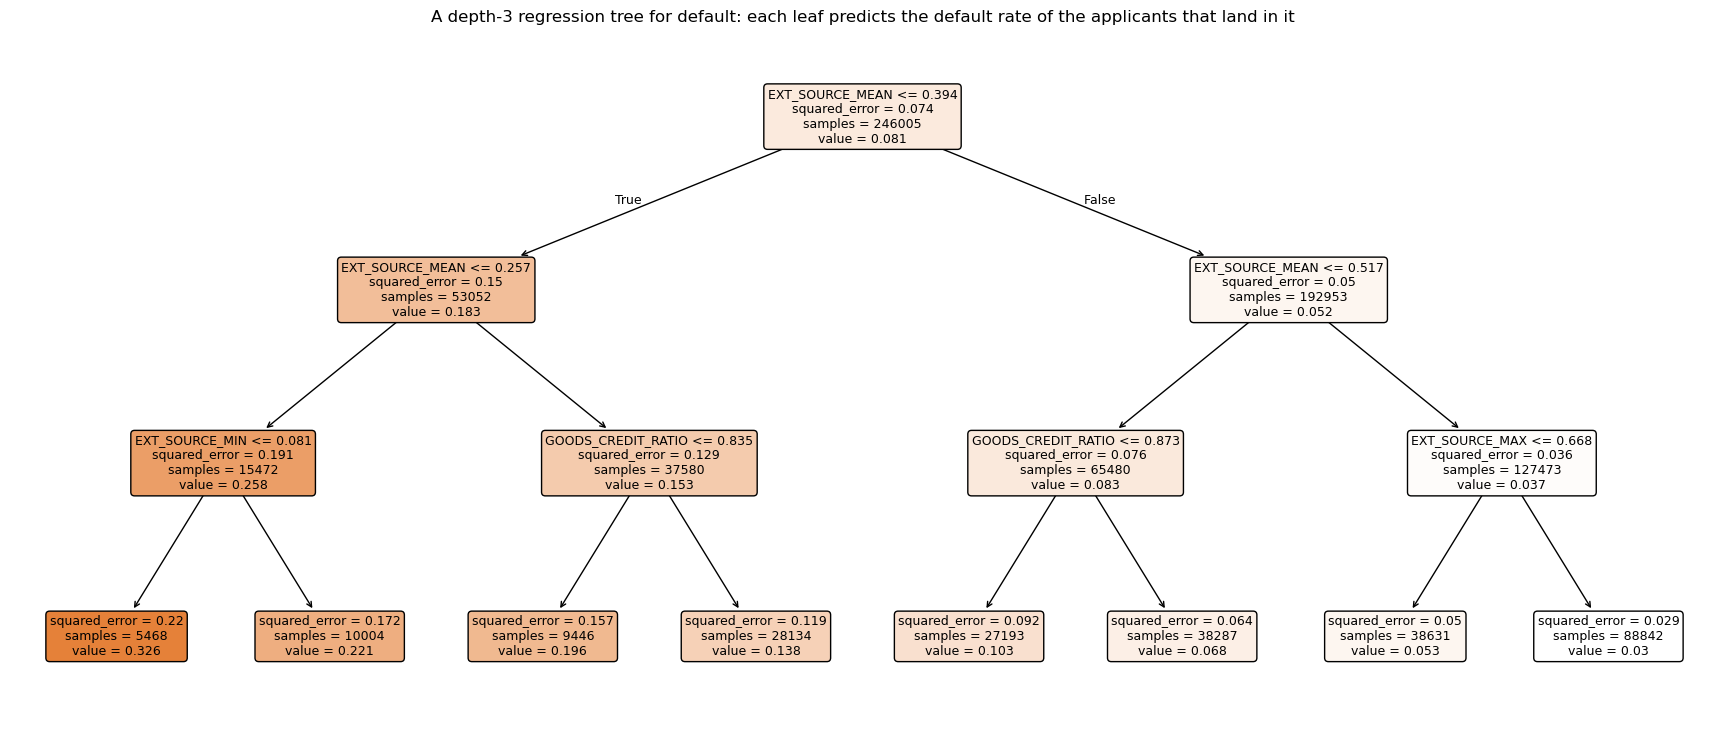

First split: EXT_SOURCE_MEAN <= 0.394
Default rate across the 8 leaves ranges from 3.0% to 32.6% (overall 8.1%)


In [34]:
# A small 3-level tree, just to show how the model reasons (the tuned tree above is the one scored).
# Each box: the rule, number of applicants, and their default rate ('value'). Darker = riskier
tree_demo = DecisionTreeRegressor(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree_demo, feature_names=list(X_train.columns), filled=True, rounded=True, fontsize=9, precision=3, ax=ax)
ax.set_title('A depth-3 regression tree for default: each leaf predicts the default rate of the applicants that land in it')
plt.show()

leaf = tree_demo.tree_.children_left == -1
leaf_rates = tree_demo.tree_.value[leaf].ravel()
print(f"First split: {X_train.columns[tree_demo.tree_.feature[0]]} <= {tree_demo.tree_.threshold[0]:.3f}")
print(f"Default rate across the {leaf.sum()} leaves ranges from {leaf_rates.min():.1%} to {leaf_rates.max():.1%} "
      f"(overall {y_train.mean():.1%})")

**Takeaway:** the tree's first question is the combined external score (`EXT_SOURCE_MEAN` ≤ 0.394). Its 8 groups range from 3.0% to 32.6% default, against 8.1% overall. Still, the full tree is the weakest model (AUC 0.725): one rate per group is too blunt to rank applicants finely.

### 8.6 XGBoost (main model)

XGBoost builds hundreds of small trees one after another, each fixing the mistakes of the last. It picks up curves and interactions the linear models miss, and still outputs a real probability. The fitting steps are in the code comments.

In [35]:
# XGBoost rejects feature names containing [, ] or <, so it gets a cleaned copy of the column names
xgb_columns = [re.sub(r'[\[\]<]', '_', c) for c in feature_names]
def to_xgb(X):
    return X.set_axis(xgb_columns, axis=1)

# Step 1: try 12 random combinations of settings, 3-fold cross-validation on AUC,
# using the 60,000-applicant tuning sample (the test set is never used for any choice)
XGB_BASE = dict(objective='binary:logistic', eval_metric='auc', tree_method='hist',
                n_jobs=-1, random_state=RANDOM_STATE)

start = time.time()
xgb_search = RandomizedSearchCV(
    XGBClassifier(n_estimators=400, **XGB_BASE),
    param_distributions={'learning_rate': [0.03, 0.05, 0.1],
                         'max_depth': [3, 4, 5, 6],
                         'min_child_weight': [1, 10, 30, 100],
                         'subsample': [0.7, 0.8, 1.0],
                         'colsample_bytree': [0.4, 0.5, 0.7],
                         'reg_lambda': [1, 2, 5, 10]},
    n_iter=12, cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring='roc_auc', random_state=RANDOM_STATE)
xgb_search.fit(to_xgb(X_tune), y_tune)
print(f'Best XGBoost settings: {xgb_search.best_params_}')
print(f'Cross-validated AUC on the tuning sample: {xgb_search.best_score_:.4f}   (tuning time {time.time()-start:.1f}s)')

Best XGBoost settings: {'subsample': 0.7, 'reg_lambda': 1, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Cross-validated AUC on the tuning sample: 0.7597   (tuning time 149.9s)


In [36]:
start = time.time()
# Step 2: keep adding trees until AUC on 10% of the TRAINING data stops improving (early stopping)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.1,
                                              random_state=RANDOM_STATE, stratify=y_train)
xgb_es = XGBClassifier(n_estimators=3000, early_stopping_rounds=100, **XGB_BASE, **xgb_search.best_params_)
xgb_es.fit(to_xgb(X_fit), y_fit, eval_set=[(to_xgb(X_val), y_val)], verbose=False)
xgb_n_trees = xgb_es.best_iteration + 1
print(f'Early stopping chose {xgb_n_trees} trees (validation AUC {xgb_es.best_score:.4f})')

# Step 3: refit on all training applicants with that number of trees, then score the test set once
xgb = XGBClassifier(n_estimators=xgb_n_trees, **XGB_BASE, **xgb_search.best_params_)
xgb.fit(to_xgb(X_train), y_train)
print(f'Fit time on full training data: {time.time()-start:.1f}s')

xgb_pred_train = xgb.predict_proba(to_xgb(X_train))[:, 1]
xgb_pred_test = xgb.predict_proba(to_xgb(X_test))[:, 1]
evaluate('6. XGBoost', xgb_pred_train, xgb_pred_test, X_train.shape[1],
         f"{xgb_n_trees} trees, depth {xgb_search.best_params_['max_depth']}, "
         f"lr {xgb_search.best_params_['learning_rate']}")

Early stopping chose 941 trees (validation AUC 0.7816)
Fit time on full training data: 74.6s
6. XGBoost:  Test AUC 0.7657 | Test R² 0.0921 | Brier 0.0674 | Train AUC 0.7941
      Precision / Recall / F1 @0.50: 0.527 / 0.021 / 0.041  |  riskiest 20%: 0.212 / 0.526 / 0.302


#### What drives XGBoost?

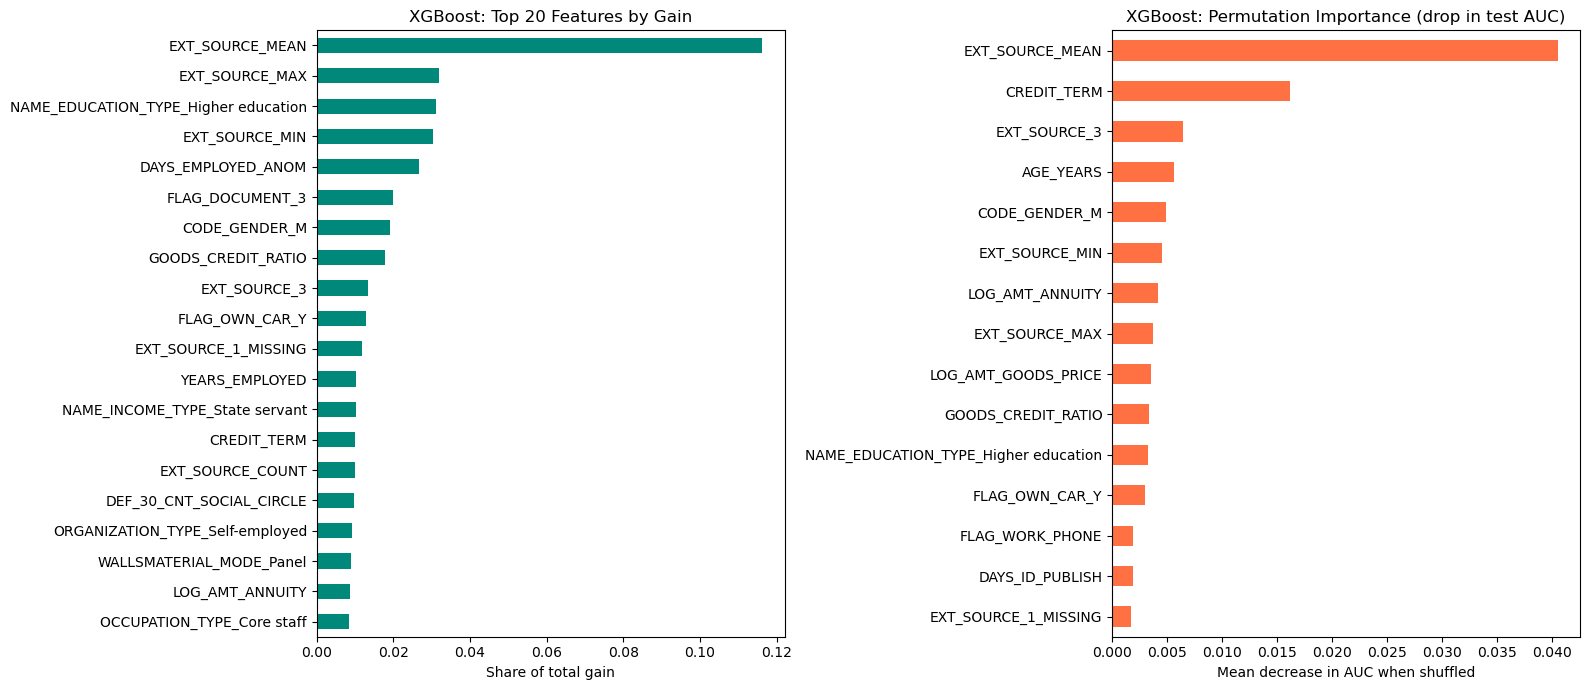

In [37]:
# Left chart: which features the trees rely on most (gain).
# Right chart: how much test AUC drops when a feature is scrambled = what the model really needs
gain = pd.Series(xgb.get_booster().get_score(importance_type='gain'))
gain.index = [feature_names[xgb_columns.index(c)] for c in gain.index]
gain = (gain / gain.sum()).sort_values(ascending=False).head(20)

pi_idx = X_test.sample(min(20_000, len(X_test)), random_state=RANDOM_STATE).index   # test sample for permutation importance
perm_xgb = permutation_importance(xgb, to_xgb(X_test.loc[pi_idx]), y_test.loc[pi_idx], scoring='roc_auc',
                                  n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
xgb_perm = pd.Series(perm_xgb.importances_mean, index=feature_names).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=100)
gain.sort_values().plot(kind='barh', color='#00897b', ax=axes[0])
axes[0].set_title('XGBoost: Top 20 Features by Gain')
axes[0].set_xlabel('Share of total gain')
xgb_perm.sort_values().plot(kind='barh', color='#ff7043', ax=axes[1])
axes[1].set_title('XGBoost: Permutation Importance (drop in test AUC)')
axes[1].set_xlabel('Mean decrease in AUC when shuffled')
plt.tight_layout()
plt.show()

In [38]:
# XGBoost's lead over the other models, in AUC points
xgb_auc = results['6. XGBoost']['Test AUC']
gaps = '  |  '.join(f"vs {name[3:]} {xgb_auc - results[name]['Test AUC']:+.4f}"
                   for name in ['1. OLS', '4. Logistic Regression (benchmark)', '3. LASSO', '5. Regression Tree'])
print(f'XGBoost test AUC {xgb_auc:.4f}  |  {gaps}')
print(f"Top 5 drivers by gain: {', '.join(gain.index[:5])}")

XGBoost test AUC 0.7657  |  vs OLS +0.0176  |  vs Logistic Regression (benchmark) +0.0159  |  vs LASSO +0.0177  |  vs Regression Tree +0.0403
Top 5 drivers by gain: EXT_SOURCE_MEAN, EXT_SOURCE_MAX, NAME_EDUCATION_TYPE_Higher education, EXT_SOURCE_MIN, DAYS_EMPLOYED_ANOM


**Takeaway:** XGBoost is the best model (AUC 0.766), 0.016 above the logistic regression benchmark and 0.018 above OLS. The external credit scores drive it, followed by repayment speed, age and gender. Gender is a sensitive attribute: removing it costs only about 0.001 AUC (Section 9.7).

## 9. Model Comparison

### 9.1 Test-set performance

In [39]:
# All six models on the same 61,502 test applicants
summary = pd.DataFrame(results).T
BENCHMARK = '4. Logistic Regression (benchmark)'
bench_auc = summary.loc[BENCHMARK, 'Test AUC']
summary['AUC vs benchmark'] = summary['Test AUC'] - bench_auc
summary['Beats benchmark?'] = np.where(summary['AUC vs benchmark'] > 0, 'Yes', 'No')
summary.loc[BENCHMARK, 'Beats benchmark?'] = 'Benchmark'

cols = ['Test AUC', 'Test Gini', 'Test R²', 'Test Brier', 'Train AUC', 'Train R²',
        'Precision @0.50', 'Recall @0.50', 'F1 @0.50',
        'Precision @top 20%', 'Recall @top 20%', 'F1 @top 20%',
        'AUC vs benchmark', 'Beats benchmark?', 'Features used', 'Notes']
summary = summary[cols]
with pd.option_context('display.float_format', '{:,.4f}'.format, 'display.max_colwidth', 60):
    display(summary)

,Test AUC,Test Gini,Test R²,Test Brier,Train AUC,Train R²,Precision @0.50,Recall @0.50,F1 @0.50,Precision @top 20%,Recall @top 20%,F1 @top 20%,AUC vs benchmark,Beats benchmark?,Features used,Notes
1. OLS,0.7480,0.4961,0.0657,0.0691,0.7516,0.0677,1.0000,0.0002,0.0004,0.2027,0.5021,0.2888,-0.0017,No,209,"All features, no regularisation"
2. Ridge,0.7480,0.4960,0.0657,0.0691,0.7516,0.0676,0.0000,0.0000,0.0000,0.2027,0.5023,0.2889,-0.0017,No,209,alpha = 10.0
3. LASSO,0.7480,0.4959,0.0657,0.0691,0.7515,0.0675,0.0000,0.0000,0.0000,0.2030,0.5029,0.2892,-0.0018,No,191,alpha = 0.00005
4. Logistic Regression (benchmark),0.7498,0.4995,0.0794,0.0683,0.7544,0.0823,0.5091,0.0113,0.0221,0.2053,0.5086,0.2925,0.0000,Benchmark,209,"L2 penalty, C = 1.0"
5. Regression Tree,0.7253,0.4507,0.0623,0.0696,0.7440,0.0719,0.0000,0.0000,0.0000,0.1922,0.4761,0.2738,-0.0244,No,27,"depth 8, min leaf 1000"
6. XGBoost,0.7657,0.5313,0.0921,0.0674,0.7941,0.1176,0.5274,0.0213,0.0410,0.2122,0.5257,0.3023,0.0159,Yes,209,"941 trees, depth 3, lr 0.05"


In [40]:
# Make the score columns numeric (they come out of the results dict as 'object')
num_cols = ['Test AUC', 'Train AUC', 'AUC vs benchmark']
summary[num_cols] = summary[num_cols].apply(pd.to_numeric)

# Grey = the logistic regression benchmark or a tie with it, green = beats it, red = worse than it
colors = ['gray' if n == BENCHMARK or abs(v) < 0.0005 else ('#2e7d32' if v > 0 else '#c62828')
          for n, v in zip(summary.index, summary['AUC vs benchmark'])]

fig = make_subplots(rows=1, cols=2, subplot_titles=('Test AUC (higher is better)',
                                                    'Train vs Test AUC (gap = overfitting)'))
fig.add_trace(go.Bar(x=summary.index, y=summary['Test AUC'], marker_color=colors,
                     text=summary['Test AUC'].round(4), textposition='outside',
                     showlegend=False), row=1, col=1)
fig.add_hline(y=bench_auc, line_dash='dash', line_color='gray', row=1, col=1,
              annotation_text='Logistic regression benchmark')
fig.add_trace(go.Bar(name='Train AUC', x=summary.index, y=summary['Train AUC'],
                     marker_color='#90caf9'), row=1, col=2)
fig.add_trace(go.Bar(name='Test AUC', x=summary.index, y=summary['Test AUC'],
                     marker_color='#1565c0'), row=1, col=2)
lo = summary[['Test AUC', 'Train AUC']].min().min()
fig.update_yaxes(range=[lo - 0.03, min(1, summary['Train AUC'].max() + 0.03)])
fig.update_layout(height=500, width=1200, barmode='group', title='Model Comparison vs the Logistic Regression Benchmark')
fig.show()

**Takeaway:** XGBoost is the only model that beats the logistic regression benchmark. OLS, Ridge and LASSO fall just short of it, and the single tree trails. XGBoost shows the biggest gap between training and test AUC (0.794 vs. 0.766), about six times the benchmark's; early stopping held it in check and its test score is still the best.

### 9.2 Are the probabilities believable?

We group test applicants into 20 risk bins and check whether each bin's predicted risk matches its actual default rate.

In [41]:
# Group test applicants into 20 risk bins and compare predicted vs actual default rate per bin.
# A bin is 'off' when the gap is bigger than chance (outside ±2 standard errors)
def binned(pred, y, n_bins=20):
    df = pd.DataFrame({'pred': np.asarray(pred, dtype=float), 'actual': np.asarray(y, dtype=float)})
    df['bin'] = pd.qcut(df['pred'].rank(method='first'), n_bins, labels=False)
    g = df.groupby('bin').agg(pred=('pred', 'mean'), actual=('actual', 'mean'), n=('actual', 'size'))
    g['resid'] = g['actual'] - g['pred']
    p = g['pred'].clip(0.001, 0.999)
    g['se'] = np.sqrt(p * (1 - p) / g['n'])
    return g

binned_preds = {name: binned(pred, y_test) for name, pred in test_preds.items()}
n_models = len(binned_preds)

diag_table = pd.DataFrame({
    'Bins outside ±2 SE (of 20)': {n: int((g['resid'].abs() > 2 * g['se']).sum()) for n, g in binned_preds.items()},
    'Largest binned residual (pct. points)': {n: g['resid'].abs().max() * 100 for n, g in binned_preds.items()},
    'Test predictions outside [0, 1] (%)': {n: ((np.asarray(p) < 0) | (np.asarray(p) > 1)).mean() * 100
                                           for n, p in test_preds.items()},
})
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(diag_table)

,Bins outside ±2 SE (of 20),Largest binned residual (pct. points),"Test predictions outside [0, 1] (%)"
1. OLS,15,8.75,12.02
2. Ridge,15,8.72,12.02
3. LASSO,15,8.74,11.88
4. Logistic Regression (benchmark),1,0.81,0.00
5. Regression Tree,3,1.37,0.00
6. XGBoost,1,1.67,0.00


**Takeaway:** logistic regression and XGBoost (1 of 20 bins off each) give believable probabilities. The OLS family misses in 15 of 20 bins and puts about 12% of applicants below 0% or above 100%.

### 9.3 Is XGBoost's lead real or luck?

In [42]:
# Resample the test applicants 200 times and re-measure each model's gap to the best one.
# If the 95% range of the gap never touches zero, the lead is real, not luck
N_BOOT = 200
best_auc_name = max(results, key=lambda n: results[n]['Test AUC'])
y_arr = y_test.to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_arr), len(y_arr)) for _ in range(N_BOOT)]

start = time.time()
p_best = np.asarray(test_preds[best_auc_name])
rows = []
for name, pred in test_preds.items():
    if name == best_auc_name:
        continue
    p = np.asarray(pred)
    diffs = [roc_auc_score(y_arr[ix], p_best[ix]) - roc_auc_score(y_arr[ix], p[ix]) for ix in boot_idx]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({'Model': name, 'AUC behind best': results[best_auc_name]['Test AUC'] - results[name]['Test AUC'],
                 '95% CI low': lo, '95% CI high': hi, 'Statistically tied with best': lo <= 0})
paired = pd.DataFrame(rows).sort_values('AUC behind best')
print(f'Bootstrap time: {time.time() - start:.1f}s')

with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(paired.set_index('Model'))
if best_auc_name != '6. XGBoost':
    xgb_row = paired.set_index('Model').loc['6. XGBoost']
    print(f"XGBoost vs {best_auc_name}: {'statistically tied' if xgb_row['Statistically tied with best'] else 'significantly behind'} "
          f"(interval {xgb_row['95% CI low']:+.4f} to {xgb_row['95% CI high']:+.4f})")
else:
    print('XGBoost has the highest test AUC; the table shows how far behind each other model is.')

Bootstrap time: 34.4s


,AUC behind best,95% CI low,95% CI high,Statistically tied with best
Model,,,,
4. Logistic Regression (benchmark),0.0159,0.0135,0.0192,False
1. OLS,0.0176,0.0146,0.0207,False
2. Ridge,0.0176,0.0146,0.0207,False
3. LASSO,0.0177,0.0146,0.0209,False
5. Regression Tree,0.0403,0.0354,0.0436,False


XGBoost has the highest test AUC; the table shows how far behind each other model is.


**Takeaway:** the lead holds in every resample. XGBoost beats logistic regression by 0.014 to 0.019 AUC and OLS by 0.015 to 0.021: statistically reliable, but small. Section 9.6 shows what it means for the applicants actually flagged.

### 9.4 Scorecard: all criteria side by side

In [43]:
# Accuracy isn't everything: a lender also has to explain decisions and trust the probabilities
TRAITS = {
    '1. OLS': ('High: one coefficient (with p-value) per feature', 'No', 'Linear probability model'),
    '2. Ridge': ('High: shrunken coefficients', 'No', 'Stabilised OLS'),
    '3. LASSO': ('Highest: only a few non-zero coefficients', 'No', 'Sparse scorecard of key drivers'),
    '4. Logistic Regression (benchmark)': ('High: coefficients read as odds ratios', 'No', 'Benchmark: industry-standard credit scorecard'),
    '5. Regression Tree': ('High: a handful of if-then rules', 'Yes, but coarse', 'Readable risk segments'),
    '6. XGBoost': ('Low: needs importance and partial-dependence plots', 'Yes', 'Main model'),
}
tied = paired.set_index('Model')['Statistically tied with best']

scorecard = pd.DataFrame({
    'Test AUC': {n: r['Test AUC'] for n, r in results.items()},
    'Test Gini': {n: r['Test Gini'] for n, r in results.items()},
    'Test Brier': {n: r['Test Brier'] for n, r in results.items()},
    'Precision (top 20%)': {n: r['Precision @top 20%'] for n, r in results.items()},
    'Recall (top 20%)': {n: r['Recall @top 20%'] for n, r in results.items()},
    'F1 (top 20%)': {n: r['F1 @top 20%'] for n, r in results.items()},
    'Train-test AUC gap': {n: r['Train AUC'] - r['Test AUC'] for n, r in results.items()},
    'Features used': {n: int(r['Features used']) for n, r in results.items()},
    'Risk groups off-calibration (of 20)': diag_table['Bins outside ±2 SE (of 20)'],
    'Invalid probabilities (%)': diag_table['Test predictions outside [0, 1] (%)'],
})
scorecard['Gap to best AUC'] = scorecard['Test AUC'].max() - scorecard['Test AUC']
scorecard['Vs. best model'] = ['Best' if n == best_auc_name else ('Tied' if tied[n] else 'Significantly worse')
                               for n in scorecard.index]
scorecard['Interpretability'] = [TRAITS[n][0] for n in scorecard.index]
scorecard['Non-linear effects'] = [TRAITS[n][1] for n in scorecard.index]
scorecard['Role'] = [TRAITS[n][2] for n in scorecard.index]
scorecard = scorecard.sort_values('Test AUC', ascending=False)

display(scorecard.style
        .format({'Test AUC': '{:.4f}', 'Test Gini': '{:.3f}', 'Test Brier': '{:.4f}', 'Precision (top 20%)': '{:.3f}', 'Recall (top 20%)': '{:.3f}', 'F1 (top 20%)': '{:.3f}', 'Train-test AUC gap': '{:+.4f}',
                 'Gap to best AUC': '{:.4f}', 'Invalid probabilities (%)': '{:.2f}'})
        .background_gradient(subset=['Test AUC'], cmap='Greens')
        .background_gradient(subset=['Test Brier', 'Train-test AUC gap'], cmap='Reds')
        .set_properties(subset=['Interpretability', 'Role'], **{'text-align': 'left'}))
scorecard.to_csv('model_scorecard.csv')

,Test AUC,Test Gini,Test Brier,Precision (top 20%),Recall (top 20%),F1 (top 20%),Train-test AUC gap,Features used,Risk groups off-calibration (of 20),Invalid probabilities (%),Gap to best AUC,Vs. best model,Interpretability,Non-linear effects,Role
6. XGBoost,0.7657,0.531,0.0674,0.212,0.526,0.302,+0.0285,209,1,0.00,0.0000,Best,Low: needs importance and partial-dependence plots,Yes,Main model
4. Logistic Regression (benchmark),0.7498,0.500,0.0683,0.205,0.509,0.292,+0.0046,209,1,0.00,0.0159,Significantly worse,High: coefficients read as odds ratios,No,Benchmark: industry-standard credit scorecard
1. OLS,0.7480,0.496,0.0691,0.203,0.502,0.289,+0.0036,209,15,12.02,0.0176,Significantly worse,High: one coefficient (with p-value) per feature,No,Linear probability model
2. Ridge,0.7480,0.496,0.0691,0.203,0.502,0.289,+0.0036,209,15,12.02,0.0176,Significantly worse,High: shrunken coefficients,No,Stabilised OLS
3. LASSO,0.7480,0.496,0.0691,0.203,0.503,0.289,+0.0035,191,15,11.88,0.0177,Significantly worse,Highest: only a few non-zero coefficients,No,Sparse scorecard of key drivers
5. Regression Tree,0.7253,0.451,0.0696,0.192,0.476,0.274,+0.0187,27,3,0.00,0.0403,Significantly worse,High: a handful of if-then rules,"Yes, but coarse",Readable risk segments


In [44]:
sc = scorecard
best, xgb_n, ols_n, lasso_n, tree_n = best_auc_name, '6. XGBoost', '1. OLS', '3. LASSO', '5. Regression Tree'
logit_n = '4. Logistic Regression (benchmark)'
most_overfit = sc['Train-test AUC gap'].idxmax()
best_brier = sc['Test Brier'].idxmin()
lin = sc.loc[['1. OLS', '2. Ridge', '3. LASSO']]

lines = [
    f"Best ranking: {best} (test AUC {sc.loc[best, 'Test AUC']:.4f}, Gini {sc.loc[best, 'Test Gini']:.3f}).",
    f"XGBoost (main model): AUC {sc.loc[xgb_n, 'Test AUC']:.4f}, {sc.loc[xgb_n, 'Test AUC'] - sc.loc[logit_n, 'Test AUC']:+.4f} vs the logistic regression benchmark; "
    + ('the best model.' if xgb_n == best else f"{sc.loc[xgb_n, 'Vs. best model'].lower()} relative to {best}."),
    f"Linear models (OLS, Ridge, LASSO) span only {lin['Test AUC'].max() - lin['Test AUC'].min():.4f} AUC; "
    f"LASSO gets there with {sc.loc[lasso_n, 'Features used']} of {sc.loc[ols_n, 'Features used']} features.",
    f"Logistic regression (benchmark): AUC {sc.loc[logit_n, 'Test AUC']:.4f}, with valid probabilities and odds-ratio coefficients; "
    f"OLS is {sc.loc[ols_n, 'Test AUC'] - sc.loc[logit_n, 'Test AUC']:+.4f} AUC vs the benchmark.",
    f"Regression tree: AUC {sc.loc[tree_n, 'Test AUC']:.4f}, {sc.loc[tree_n, 'Gap to best AUC']:.4f} behind the best; useful for its rules, not its accuracy.",
    f"Most overfitted: {most_overfit} (training AUC {sc.loc[most_overfit, 'Train-test AUC gap']:+.4f} above test).",
    f"Most accurate probabilities (lowest Brier): {best_brier} ({sc.loc[best_brier, 'Test Brier']:.4f}).",
    f"Best flags when reviewing the riskiest 20% (highest F1): {sc['F1 (top 20%)'].idxmax()} "
    f"(precision {sc.loc[sc['F1 (top 20%)'].idxmax(), 'Precision (top 20%)']:.3f}, recall {sc.loc[sc['F1 (top 20%)'].idxmax(), 'Recall (top 20%)']:.3f}, "
    f"F1 {sc['F1 (top 20%)'].max():.3f}).",
    f"Invalid probabilities: OLS puts {sc.loc[ols_n, 'Invalid probabilities (%)']:.2f}% of test predictions outside [0, 1]; "
    f"XGBoost {sc.loc[xgb_n, 'Invalid probabilities (%)']:.2f}%.",
]
print('How the models compare (this run):\n')
for line in lines:
    print(' -', line)

How the models compare (this run):

 - Best ranking: 6. XGBoost (test AUC 0.7657, Gini 0.531).
 - XGBoost (main model): AUC 0.7657, +0.0159 vs the logistic regression benchmark; the best model.
 - Linear models (OLS, Ridge, LASSO) span only 0.0001 AUC; LASSO gets there with 191 of 209 features.
 - Logistic regression (benchmark): AUC 0.7498, with valid probabilities and odds-ratio coefficients; OLS is -0.0017 AUC vs the benchmark.
 - Regression tree: AUC 0.7253, 0.0403 behind the best; useful for its rules, not its accuracy.
 - Most overfitted: 6. XGBoost (training AUC +0.0285 above test).
 - Most accurate probabilities (lowest Brier): 6. XGBoost (0.0674).
 - Best flags when reviewing the riskiest 20% (highest F1): 6. XGBoost (precision 0.212, recall 0.526, F1 0.302).
 - Invalid probabilities: OLS puts 12.02% of test predictions outside [0, 1]; XGBoost 0.00%.


### 9.5 Business view: does XGBoost find the risky applicants?

We rank test applicants from safest to riskiest and split them into 10 equal groups. A good model packs the defaults into the riskiest groups.

Main model: 6. XGBoost (test AUC 0.7657). Highest test AUC this run: 6. XGBoost (0.7657)


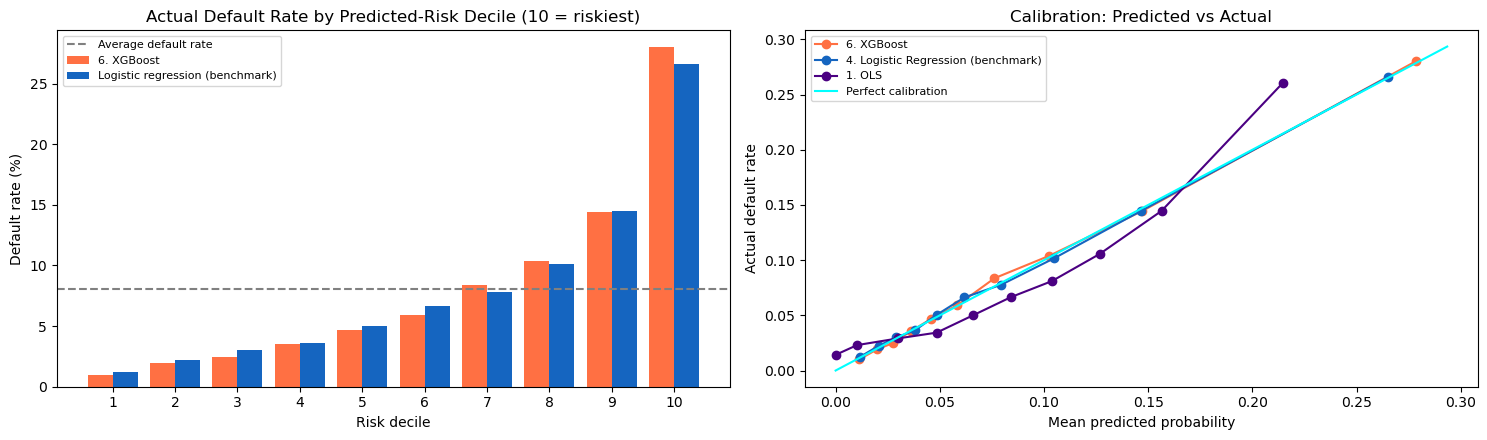

Share of all test defaults in the riskiest 20% of applicants: 6. XGBoost 52.6% vs logistic regression benchmark 50.9%


In [45]:
MAIN_MODEL = '6. XGBoost'
print(f'Main model: {MAIN_MODEL} (test AUC {results[MAIN_MODEL]["Test AUC"]:.4f}). '
      f'Highest test AUC this run: {best_auc_name} ({results[best_auc_name]["Test AUC"]:.4f})')

# Rank test applicants from safest (1) to riskiest (10) and check the actual default rate in each group
def decile_table(pred):
    risk_decile = pd.qcut(pd.Series(pred).rank(method='first'), 10, labels=range(1, 11)).values
    return (pd.DataFrame({'decile': risk_decile, 'default': y_test.values})
              .groupby('decile', observed=True)['default'].agg(['mean', 'sum']))

best_dec = decile_table(test_preds[MAIN_MODEL])
bench_dec = decile_table(test_preds['4. Logistic Regression (benchmark)'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), dpi=100)
w = 0.4
axes[0].bar(best_dec.index.astype(int) - w/2, best_dec['mean'] * 100, w, label=MAIN_MODEL, color='#ff7043')
axes[0].bar(bench_dec.index.astype(int) + w/2, bench_dec['mean'] * 100, w, label='Logistic regression (benchmark)', color='#1565c0')
axes[0].axhline(y_test.mean() * 100, color='gray', linestyle='--', label='Average default rate')
axes[0].set_xticks(range(1, 11))
axes[0].set_title('Actual Default Rate by Predicted-Risk Decile (10 = riskiest)')
axes[0].set_xlabel('Risk decile'); axes[0].set_ylabel('Default rate (%)'); axes[0].legend(fontsize=8)

axes[1].set_title('Calibration: Predicted vs Actual')
for name, color in [(MAIN_MODEL, '#ff7043'), ('4. Logistic Regression (benchmark)', '#1565c0'), ('1. OLS', 'indigo')]:
    frac_pos, mean_pred = calibration_curve(y_test, np.clip(test_preds[name], 0, 1), n_bins=10, strategy='quantile')
    axes[1].plot(mean_pred, frac_pos, marker='o', label=name, color=color)
lim = [0, max(axes[1].get_xlim()[1], axes[1].get_ylim()[1])]
axes[1].plot(lim, lim, color='cyan', label='Perfect calibration')
axes[1].set_xlabel('Mean predicted probability'); axes[1].set_ylabel('Actual default rate')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

top2_best = best_dec.loc[[9, 10], 'sum'].sum() / best_dec['sum'].sum()
top2_bench = bench_dec.loc[[9, 10], 'sum'].sum() / bench_dec['sum'].sum()
print(f'Share of all test defaults in the riskiest 20% of applicants: '
      f'{MAIN_MODEL} {top2_best:.1%} vs logistic regression benchmark {top2_bench:.1%}')

**Takeaway:** the riskiest 20% of applicants by XGBoost hold 52.6% of all defaults (logistic regression benchmark: 50.9%). Reviewing just that group would catch over half of future problem loans.

### 9.6 Precision, recall and F1 at two cut-offs

AUC measures ranking. Once a cut-off is chosen, each applicant is either flagged or not, and three measures describe the result:
* **Precision:** of the applicants flagged, the share who actually default.
* **Recall:** of all actual defaulters, the share the model flags.
* **F1:** the balance of the two (their harmonic mean); 1.0 is perfect.

We compare two cut-offs: the default **0.50 probability**, and **flagging the riskiest 20%** of applicants (the review group from Section 9.5).

In [46]:
# Precision, recall and F1 for every model at both cut-offs (computed in evaluate(), Section 7)
metric_cols = [f'{m} {c}' for c in ['@0.50', '@top 20%'] for m in ['Precision', 'Recall', 'F1']]
flag_table = pd.DataFrame(results).T[metric_cols].apply(pd.to_numeric)
flag_table.columns = pd.MultiIndex.from_tuples([('0.50 cut-off' if '@0.50' in c else 'Riskiest 20%', c.split(' @')[0])
                                                for c in metric_cols])
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(flag_table)

# XGBoost confusion matrices at both cut-offs: who gets flagged, and who is right
xgb_p = np.asarray(test_preds['6. XGBoost'], dtype=float)
xgb_flags = {'0.50 cut-off': (xgb_p >= 0.5).astype(int),
             'Riskiest 20%': (pd.Series(xgb_p).rank(method='first') > 0.8 * len(xgb_p)).astype(int).values}
for label, flag in xgb_flags.items():
    tn, fp, fn, tp = confusion_matrix(y_test, flag).ravel()
    print(f"XGBoost, {label}: flagged {tp + fp:,} ({(tp + fp) / len(flag):.1%}) | defaults caught {tp:,} of {tp + fn:,} "
          f"| good borrowers flagged {fp:,} | precision {tp / max(tp + fp, 1):.3f} | recall {tp / (tp + fn):.3f} "
          f"| F1 {f1_score(y_test, flag, zero_division=0):.3f}")

0.50 cut-off              Riskiest 20%  \
                                      Precision Recall    F1    Precision   
1. OLS                                    1.000  0.000 0.000        0.203   
2. Ridge                                  0.000  0.000 0.000        0.203   
3. LASSO                                  0.000  0.000 0.000        0.203   
4. Logistic Regression (benchmark)        0.509  0.011 0.022        0.205   
5. Regression Tree                        0.000  0.000 0.000        0.192   
6. XGBoost                                0.527  0.021 0.041        0.212   

                                                 
                                   Recall    F1  
1. OLS                              0.502 0.289  
2. Ridge                            0.502 0.289  
3. LASSO                            0.503 0.289  
4. Logistic Regression (benchmark)  0.509 0.292  
5. Regression Tree                  0.476 0.274  
6. XGBoost                          0.526 0.302

XGBoost, 0.50 cut-off: flagged 201 (0.3%) | defaults caught 106 of 4,965 | good borrowers flagged 95 | precision 0.527 | recall 0.021 | F1 0.041
XGBoost, Riskiest 20%: flagged 12,301 (20.0%) | defaults caught 2,610 of 4,965 | good borrowers flagged 9,691 | precision 0.212 | recall 0.526 | F1 0.302


**Takeaway:** at the default 0.50 cut-off every model is close to useless as a flag. XGBoost flags only 201 applicants (0.3%) and catches 106 of 4,965 defaulters (recall 2.1%, F1 0.041); logistic regression catches 1.1%, and OLS, Ridge, LASSO and the tree catch almost none. Their precision near 50% looks good only because so few applicants are flagged.

Flagging the riskiest 20% changes the picture. XGBoost catches 2,610 defaulters (recall 52.6%) and 21.2% of the applicants it flags default, 2.6 times the 8.07% average. Its F1 of 0.302 is the best of the six, ahead of the logistic regression benchmark (0.292, 2,525 defaulters caught): fewer than one extra defaulter per 100 applicants flagged. Even XGBoost flags about 3.7 good borrowers for every defaulter it catches.

### 9.7 Gender check

Sex is a prohibited ground for credit decisions, so we retrain XGBoost with exactly the same settings and number of trees but without the gender columns. The cell also saves the hold-out predictions and feature importance used in the report.

In [47]:
gender_cols = [c for c in feature_names if c.startswith('CODE_GENDER')]
keep_cols = [c for c in feature_names if c not in gender_cols]
keep_xgb = [xgb_columns[list(feature_names).index(c)] for c in keep_cols]

# Same settings and number of trees as the main XGBoost model, gender removed
xgb_ng = XGBClassifier(n_estimators=xgb_n_trees, **XGB_BASE, **xgb_search.best_params_)
xgb_ng.fit(to_xgb(X_train)[keep_xgb], y_train)
ng_pred_test = xgb_ng.predict_proba(to_xgb(X_test)[keep_xgb])[:, 1]
print(f'XGBoost without gender: test AUC {roc_auc_score(y_test, ng_pred_test):.4f} '
      f'(with gender {roc_auc_score(y_test, xgb_pred_test):.4f})')

pd.DataFrame({'TARGET': y_test.values,
              'xgb': xgb_pred_test,
              'xgb_no_gender': ng_pred_test},
             index=X_test.index).to_csv('agnes_xgb_preds.csv')
print('Saved agnes_xgb_preds.csv  ->  put it in the "867 fins" folder')

# Save XGBoost's hold-out predictions and feature importance for the report
pd.DataFrame({'perm_importance': perm_xgb.importances_mean,
              'perm_std': perm_xgb.importances_std},
             index=feature_names).sort_values('perm_importance', ascending=False).to_csv('agnes_xgb_importance.csv')
print('Saved agnes_xgb_importance.csv  ->  put it in the "867 fins" folder too')

XGBoost without gender: test AUC 0.7644 (with gender 0.7657)
Saved agnes_xgb_preds.csv  ->  put it in the "867 fins" folder
Saved agnes_xgb_importance.csv  ->  put it in the "867 fins" folder too


**Takeaway:** removing gender lowers XGBoost's test AUC from 0.766 to 0.764, a small but measurable loss (paired bootstrap: -0.0022 to -0.0001). Gender should be removed before deployment.

### 9.8 Binned logistic scorecard: can an explainable model close the gap?

The standard credit-scorecard format: the 16 most important continuous features enter as ten equal-sized bands each (cut on the training data), so effects such as repayment speed can bend, and four duplicate affordability features are dropped. Everything else is as in the logistic regression benchmark of Section 8.4.

In [48]:
# Binned logistic scorecard: 16 key continuous features enter as 10 equal-sized bands each; 4 duplicate affordability features dropped
# Uses X_train, X_test, y_train, y_test, logit_pred_test and xgb_pred_test from earlier cells.
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score
 
# 20 most important continuous features (XGBoost permutation importance), less 4 duplicate affordability features
BIN_FEATURES = ['EXT_SOURCE_MEAN', 'CREDIT_TERM', 'EXT_SOURCE_3', 'AGE_YEARS', 'EXT_SOURCE_MIN', 'EXT_SOURCE_MAX',
                'GOODS_CREDIT_RATIO', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'YEARS_EMPLOYED', 'EXT_SOURCE_1',
                'INCOME_PER_PERSON', 'EXT_SOURCE_2', 'EMPLOYED_AGE_RATIO', 'YEARS_BEGINEXPLUATATION_AVG', 'DAYS_REGISTRATION']
DUPLICATES = ['LOG_AMT_ANNUITY', 'LOG_AMT_GOODS_PRICE', 'ANNUITY_INCOME_RATIO', 'LOG_AMT_CREDIT']
 
bins = KBinsDiscretizer(n_bins=10, encode='onehot-dense', strategy='quantile', subsample=None)
bins_train = bins.fit_transform(X_train[BIN_FEATURES]); bins_test = bins.transform(X_test[BIN_FEATURES])   # cut points from training data only
linear = [c for c in X_train.columns if c not in BIN_FEATURES + DUPLICATES]
scaler = StandardScaler().fit(X_train[linear])
S_train = np.c_[scaler.transform(X_train[linear]), bins_train]
S_test = np.c_[scaler.transform(X_test[linear]), bins_test]
 
# penalty chosen by 3-fold CV on AUC (first 80,000 training applicants, to save time)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_auc = {C: cross_val_score(LogisticRegression(C=C, max_iter=3000), S_train[:80000], y_train.values[:80000],
                             cv=cv, scoring='roc_auc').mean() for C in [0.01, 0.1, 1.0]}
best_C_card = max(cv_auc, key=cv_auc.get)
scorecard = LogisticRegression(C=best_C_card, max_iter=3000).fit(S_train, y_train)
card_pred_test = scorecard.predict_proba(S_test)[:, 1]
card_pred_train = scorecard.predict_proba(S_train)[:, 1]
 
def top20(pred):
    flag = np.zeros(len(pred), int); flag[np.argsort(-np.asarray(pred))[:int(round(0.2 * len(pred)))]] = 1
    return precision_score(y_test, flag), recall_score(y_test, flag), f1_score(y_test, flag)
 
print(f'Binned scorecard: C = {best_C_card}, {S_train.shape[1]} inputs')
print(f'Test AUC {roc_auc_score(y_test, card_pred_test):.4f} | Train AUC {roc_auc_score(y_train, card_pred_train):.4f} | '
      f'Brier {brier_score_loss(y_test, card_pred_test):.4f}')
for name, p in [('Logistic regression', logit_pred_test), ('Binned scorecard', card_pred_test), ('XGBoost', xgb_pred_test)]:
    pr, rc, f1 = top20(p)
    print(f'{name:20s} AUC {roc_auc_score(y_test, p):.4f} | riskiest 20%: precision {pr:.3f}, recall {rc:.3f}, F1 {f1:.3f}')
 
# paired bootstrap: scorecard vs logistic regression (same 200 resamples as Section 9.3)
y_arr = y_test.to_numpy(); rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_arr), len(y_arr)) for _ in range(200)]
diffs = [roc_auc_score(y_arr[ix], card_pred_test[ix]) - roc_auc_score(y_arr[ix], np.asarray(logit_pred_test)[ix]) for ix in boot_idx]
print(f'Scorecard minus logistic regression: {roc_auc_score(y_test, card_pred_test) - roc_auc_score(y_test, logit_pred_test):+.4f} '
      f'(95% range {np.percentile(diffs, 2.5):+.4f} to {np.percentile(diffs, 97.5):+.4f})')

Binned scorecard: C = 0.01, 336 inputs
Test AUC 0.7538 | Train AUC 0.7588 | Brier 0.0681
Logistic regression  AUC 0.7498 | riskiest 20%: precision 0.205, recall 0.509, F1 0.292
Binned scorecard     AUC 0.7538 | riskiest 20%: precision 0.206, recall 0.510, F1 0.293
XGBoost              AUC 0.7657 | riskiest 20%: precision 0.212, recall 0.525, F1 0.302
Scorecard minus logistic regression: +0.0041 (95% range +0.0024 to +0.0059)


**Takeaway:** the scorecard lifts AUC from 0.750 to 0.754 (95% range +0.002 to +0.006) with F1 0.293 when flagging the riskiest 20%, recovering about a quarter of XGBoost's lead while staying fully explainable: each band carries its own weight, and an applicant's score is the sum of their band weights.

## 10. Conclusions

* **XGBoost ranks risk best** (AUC 0.766, Gini 0.531), about 0.016 AUC and 0.010 F1 ahead of logistic regression. The lead is statistically real (Section 9.3) but small in practice: fewer than one extra defaulter caught per 100 applicants flagged (Section 9.6).
* **When accuracy is this close, explainability decides.** Logistic regression models the 0/1 outcome directly, overfits least, and its predicted rates sit closest to actual default rates; the binned scorecard narrows the gap further (Section 9.8). It is the better decision model, with XGBoost kept as a challenger.
* **OLS, Ridge and LASSO add nothing.** They fall just short of logistic regression and give 12% of applicants impossible probabilities.
* **A single tree is the weakest model,** but its rules show clearly which factors split risk first.
* **External credit scores drive every model,** followed by repayment speed, age and education.
* **The default 50% cut-off is wrong** for an 8% default rate; flagging the riskiest 20% catches over half of defaults.

## 11. Recommendations

1. **Adopt the binned logistic scorecard as the decision model** and use it to set review intensity: send the riskiest 20% to manual review and fast-track the lowest-risk groups, giving each decision its reasons (Sections 9.6 and 9.8).
2. **Run XGBoost as a challenger** on the same applicants, and switch only if its extra defaults caught are worth more than the cost of explaining and governing a less transparent model.
3. **Set the cut-off from business costs, not the default 0.50.** Flag an applicant when predicted risk exceeds margin ÷ (loss given default + margin), and track precision and recall at that cut-off.
4. **Remove gender before deployment** (it costs only about 0.001 AUC, Section 9.7), audit approval rates by group for proxy effects, and review age with legal counsel.
5. **Monitor and retrain.** Track AUC, precision, recall and calibration on new applicants every quarter, and retrain when they slip.

**Future work:** add the credit-history tables (previous loans, repayment records), which may change the size of XGBoost's lead, and validate on applicants from a later period.